# Dimensions: From a Research Grant to Associated Patents

Dimensions connects several kinds of research and innovation information, including grants, publications, researchers, organizations, and patents.

In this workbook, we will investigate one simple relationship:

> **Can we start with a research grant and find patents that Dimensions associates with it?**

We will:

- connect to the Dimensions API
- retrieve one known grant
- inspect information about the grant
- use the Dimensions grant ID to find associated patents
- inspect the patent records
- create a pandas DataFrame
- make a simple visualization of the linked patents

The goal is to understand the relationship between a grant record and patent records without building a large or complicated patent landscape.


## 1. Setup

This notebook uses the `dimcli` Python package to communicate with the Dimensions API.

Access to the Dimensions API requires an API key and appropriate Dimensions access through your institution.

For this workshop, store your API key in a `config.yml` file in the same directory as the notebook:

```yaml
dimensions_api_key: YOUR_DIMENSIONS_API_KEY
```

The notebook will read the API key from this file rather than storing it directly in the notebook.

Do not commit `config.yml` or other files containing API keys to a public repository.


In [1]:
import yaml
import pandas as pd
import dimcli

with open("config.yml", "r") as f:
    config = yaml.safe_load(f)

API_KEY = config["dimensions_api_key"]

dimcli.login(
    key=API_KEY,
    endpoint="https://app.dimensions.ai"
)

dsl = dimcli.Dsl()


Dimcli - Dimensions API Client (v1.8)
Connected to: <https://app.dimensions.ai/api/dsl> - DSL v2.16
Method: manual login


## 2. Start With One Grant

For this example, we will use a grant that has patent relationships in Dimensions:

**The Dynamics of Human Atrial Fibrillation**

Its Dimensions grant ID is:

`grant.2540843`

A Dimensions ID gives us a precise way to retrieve the grant and follow relationships to other records.


In [2]:
GRANT_ID = "grant.2540843"


Retrieve a few useful fields describing the grant.


In [3]:
grant_query = f'''
search grants
where id="{GRANT_ID}"
return grants[
    id
    + title
    + funder_org_name
    + funding_usd
    + start_date
    + end_date
    + research_org_names
]
'''

grant_result = dsl.query(grant_query)


Returned Grants: 1 (total = 1)
Time: 0.50s


## 3. Inspect the Grant Record

Look at the returned grant data before doing anything else with it.


In [4]:
grant_result.grants


[{'end_date': '2031-03-31',
  'funder_org_name': 'National Heart Lung and Blood Institute',
  'funding_usd': 7889597.0,
  'id': 'grant.2540843',
  'research_org_names': ['Stanford University'],
  'start_date': '2005-12-01',
  'title': 'The Dynamics of Human Atrial Fibrillation'}]

Because we searched for one specific Dimensions grant ID, we expect one grant record.


In [5]:
grant = grant_result.grants[0]

grant


{'end_date': '2031-03-31',
 'funder_org_name': 'National Heart Lung and Blood Institute',
 'funding_usd': 7889597.0,
 'id': 'grant.2540843',
 'research_org_names': ['Stanford University'],
 'start_date': '2005-12-01',
 'title': 'The Dynamics of Human Atrial Fibrillation'}

Print a few fields in a more readable form.


In [6]:
print("Title:", grant.get("title"))
print("Funder:", grant.get("funder_org_name"))
print("Funding (USD):", grant.get("funding_usd"))
print("Start date:", grant.get("start_date"))
print("End date:", grant.get("end_date"))
print("Research organizations:", grant.get("research_org_names"))


Title: The Dynamics of Human Atrial Fibrillation
Funder: National Heart Lung and Blood Institute
Funding (USD): 7889597.0
Start date: 2005-12-01
End date: 2031-03-31
Research organizations: ['Stanford University']


## 4. Find Patents Associated With the Grant

Dimensions patent records can contain an `associated_grant_ids` field.

This creates a direct connection between patent information and grant information.

We can therefore search the patents data source for records whose `associated_grant_ids` field contains our grant ID.


In [7]:
patent_query = f'''
search patents
where associated_grant_ids="{GRANT_ID}"
return patents[
    id
    + title
    + filing_date
    + publication_date
    + granted_date
    + inventor_names
    + assignee_names
    + legal_status
    + cpc
    + associated_grant_ids
]
limit 100
'''

patent_result = dsl.query(patent_query)


Returned Patents: 96 (total = 96)
Time: 1.53s


## 5. Inspect the Patent Results

First, look at the returned patent records.


In [8]:
patent_result.patents[:5]


[{'assignee_names': ['United States Department of Veterans Affairs',
   'University of California, San Diego'],
  'associated_grant_ids': ['grant.2419549', 'grant.2540843'],
  'cpc': ['A61B18/1206',
   'A61B18/1492',
   'A61B2018/00214',
   'A61B2018/00351',
   'A61B2018/00357',
   'A61B2018/00375',
   'A61B2018/00839',
   'A61B2018/1435',
   'A61B5/02',
   'A61B5/02405',
   'A61B5/02416',
   'A61B5/0245',
   'A61B5/04',
   'A61B5/04007',
   'A61B5/04011',
   'A61B5/04012',
   'A61B5/0402',
   'A61B5/042',
   'A61B5/0422',
   'A61B5/044',
   'A61B5/0452',
   'A61B5/04525',
   'A61B5/046',
   'A61B5/0464',
   'A61B5/243',
   'A61B5/283',
   'A61B5/287',
   'A61B5/339',
   'A61B5/341',
   'A61B5/349',
   'A61B5/35',
   'A61B5/361',
   'A61B5/363',
   'A61B5/4836',
   'A61B5/6857',
   'A61B5/6858',
   'A61B5/6859',
   'A61B5/7203',
   'A61B5/7235',
   'A61B5/726',
   'A61B5/7405',
   'A61B7/04',
   'A61B8/0883'],
  'filing_date': '2016-06-08',
  'granted_date': '2018-05-01',
  'id': 'US-9

How many patent records were returned?


In [9]:
len(patent_result.patents)


96

Print the titles of the associated patents.


In [10]:
for patent in patent_result.patents:
    print(patent.get("title"))


System for analysis of complex rhythm disorders
System and method for reconstructing cardiac activation information
System and method of identifying sources for biological rhythms
Method and system for detection of biological rhythm disorders
System and method for reconstructing cardiac activation information
System and method for targeting heart rhythm disorders using shaped ablation
System and method for reconstructing cardiac signals associated with a complex rhythm disorder
System and method for reconstructing cardiac activation information
Method for analysis of complex rhythm disorders
System and method of identifying sources for biological rhythms
System and method for reconstructing cardiac activation information
Methods and systems for detecting and treating heart instability
System and method of identifying sources for biological rhythms
Methods for detecting biological rhythm disorders
System for analysis of complex rhythm disorders
System and method to identify sources asso

The important step in this workbook is already visible:

**Grant ID → associated patent records**

Dimensions allows us to move between different kinds of research and innovation information using relationships stored in the database.


## 6. Create a pandas DataFrame

Convert the returned patent records into a DataFrame.


In [11]:
patents_df = patent_result.as_dataframe()

patents_df.head()


,id,title,assignee_names,associated_grant_ids,cpc,filing_date,granted_date,inventor_names,legal_status,publication_date
0,US-9955879-B2,System for analysis of complex rhythm disorders,"[United States Department of Veterans Affairs,...","[grant.2419549, grant.2540843]","[A61B18/1206, A61B18/1492, A61B2018/00214, A61...",2016-06-08,2018-05-01,"[NARAYAN SANJIV, RAPPEL WOUTER-JAN]",Active,2018-05-01
1,US-9913615-B2,System and method for reconstructing cardiac a...,"[United States Department of Veterans Affairs,...","[grant.2540843, grant.2421231]","[A61B2562/046, A61B5/0036, A61B5/0205, A61B5/0...",2016-11-04,2018-03-13,"[NARAYAN SANJIV M, BRIGGS CAREY ROBERT, SEHRA ...",Active,2018-03-13
2,US-9724009-B2,System and method of identifying sources for b...,"[United States Department of Veterans Affairs,...","[grant.2540843, grant.2421231]","[A61B5/002, A61B5/02405, A61B5/04011, A61B5/04...",2014-10-06,2017-08-08,"[NARAYAN SANJIV, BRIGGS CAREY ROBERT]",Active,2017-08-08
3,US-9717436-B2,Method and system for detection of biological ...,"[United States Department of Veterans Affairs,...",[grant.2540843],"[A61B5/0255, A61B5/04011, A61B5/04012, A61B5/0...",2014-08-29,2017-08-01,"[NARAYAN SANJIV, SEHRA RUCHIR]",Active,2017-08-01
4,US-9668666-B2,System and method for reconstructing cardiac a...,"[United States Department of Veterans Affairs,...","[grant.2540843, grant.2421231]","[A61B2562/046, A61B5/0036, A61B5/0205, A61B5/0...",2015-11-17,2017-06-06,"[NARAYAN SANJIV, BRIGGS CAREY ROBERT, SEHRA RU...",Active,2017-06-06


Inspect the columns and size of the dataset.


In [12]:
patents_df.shape


(96, 10)

In [13]:
patents_df.columns


Index(['id', 'title', 'assignee_names', 'associated_grant_ids', 'cpc',
       'filing_date', 'granted_date', 'inventor_names', 'legal_status',
       'publication_date'],
      dtype='object')

Select a few fields that are easy to interpret.


In [14]:
patents_df[[
    "id",
    "title",
    "filing_date",
    "inventor_names",
    "assignee_names",
    "legal_status"
]].head(10)


,id,title,filing_date,inventor_names,assignee_names,legal_status
0,US-9955879-B2,System for analysis of complex rhythm disorders,2016-06-08,"[NARAYAN SANJIV, RAPPEL WOUTER-JAN]","[United States Department of Veterans Affairs,...",Active
1,US-9913615-B2,System and method for reconstructing cardiac a...,2016-11-04,"[NARAYAN SANJIV M, BRIGGS CAREY ROBERT, SEHRA ...","[United States Department of Veterans Affairs,...",Active
2,US-9724009-B2,System and method of identifying sources for b...,2014-10-06,"[NARAYAN SANJIV, BRIGGS CAREY ROBERT]","[United States Department of Veterans Affairs,...",Active
3,US-9717436-B2,Method and system for detection of biological ...,2014-08-29,"[NARAYAN SANJIV, SEHRA RUCHIR]","[United States Department of Veterans Affairs,...",Active
4,US-9668666-B2,System and method for reconstructing cardiac a...,2015-11-17,"[NARAYAN SANJIV, BRIGGS CAREY ROBERT, SEHRA RU...","[United States Department of Veterans Affairs,...",Active
5,US-9655535-B2,System and method for targeting heart rhythm d...,2016-02-18,"[NARAYAN SANJIV, BRIGGS CAREY ROBERT]","[United States Department of Veterans Affairs,...",Active
6,US-9549684-B2,System and method for reconstructing cardiac s...,2015-12-10,"[NARAYAN SANJIV, SEHRA RUCHIR]","[United States Department of Veterans Affairs,...",Active
7,US-9468387-B2,System and method for reconstructing cardiac a...,2015-05-28,"[NARAYAN SANJIV, BRIGGS CAREY ROBERT]","[United States Department of Veterans Affairs,...",Active
8,US-9439573-B2,Method for analysis of complex rhythm disorders,2014-08-29,"[NARAYAN SANJIV, RAPPEL WOUTER-JAN]","[United States Department of Veterans Affairs,...",Active
9,US-9408536-B2,System and method of identifying sources for b...,2012-07-27,"[NARAYAN SANJIV, BRIGGS CAREY ROBERT]","[United States Department of Veterans Affairs,...",Active


## 7. Patent Filing Activity

Because this query is specifically retrieving the patents associated with one grant, we can look at the filing dates represented in this linked set.

First, convert the filing date to a pandas date.


In [15]:
patents_df["filing_date"] = pd.to_datetime(
    patents_df["filing_date"],
    errors="coerce"
)

patents_df["filing_year"] = patents_df["filing_date"].dt.year


Count the linked patent records by filing year.


In [16]:
patents_by_year = (
    patents_df["filing_year"]
    .value_counts()
    .sort_index()
)

patents_by_year


2009     3
2011     3
2012     8
2013    17
2014    16
2015    14
2016    18
2017     7
2018     3
2019     4
2021     2
2023     1
Name: filing_year, dtype: int64

Create a simple bar chart.


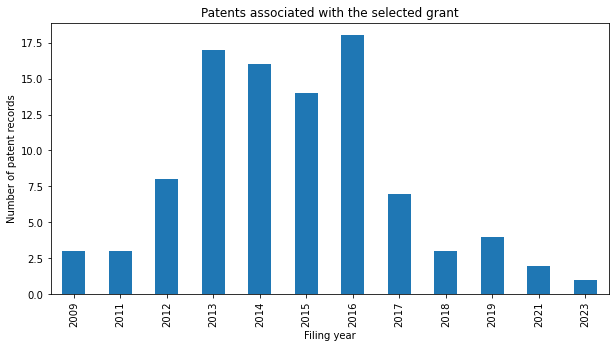

In [17]:
patents_by_year.plot(
    kind="bar",
    xlabel="Filing year",
    ylabel="Number of patent records",
    title="Patents associated with the selected grant",
    figsize=(10, 5)
);


### A note about interpretation

Dimensions is showing us a **database relationship** between this grant and these patent records.

That relationship is interesting, but it does not by itself establish that:

- the grant directly caused the patented invention
- every patent resulting from the funded research is represented here
- each patent record represents a distinct invention
- the patents necessarily resulted in a commercial product or license

Patent families, funding acknowledgments, data coverage, and the meaning of the grant–patent relationship all matter when moving toward a more complete analysis.

For this introductory exercise, the important point is simply that Dimensions lets us identify and retrieve these linked records programmatically.


## 8. Look More Closely at One Patent

Choose one of the returned patent records and inspect it directly.


In [18]:
patent = patent_result.patents[0]

patent


{'assignee_names': ['United States Department of Veterans Affairs',
  'University of California, San Diego'],
 'associated_grant_ids': ['grant.2419549', 'grant.2540843'],
 'cpc': ['A61B18/1206',
  'A61B18/1492',
  'A61B2018/00214',
  'A61B2018/00351',
  'A61B2018/00357',
  'A61B2018/00375',
  'A61B2018/00839',
  'A61B2018/1435',
  'A61B5/02',
  'A61B5/02405',
  'A61B5/02416',
  'A61B5/0245',
  'A61B5/04',
  'A61B5/04007',
  'A61B5/04011',
  'A61B5/04012',
  'A61B5/0402',
  'A61B5/042',
  'A61B5/0422',
  'A61B5/044',
  'A61B5/0452',
  'A61B5/04525',
  'A61B5/046',
  'A61B5/0464',
  'A61B5/243',
  'A61B5/283',
  'A61B5/287',
  'A61B5/339',
  'A61B5/341',
  'A61B5/349',
  'A61B5/35',
  'A61B5/361',
  'A61B5/363',
  'A61B5/4836',
  'A61B5/6857',
  'A61B5/6858',
  'A61B5/6859',
  'A61B5/7203',
  'A61B5/7235',
  'A61B5/726',
  'A61B5/7405',
  'A61B7/04',
  'A61B8/0883'],
 'filing_date': '2016-06-08',
 'granted_date': '2018-05-01',
 'id': 'US-9955879-B2',
 'inventor_names': ['NARAYAN SANJIV',

You might look at:

- the patent title
- inventors
- assignees
- filing and publication dates
- legal status
- CPC classifications
- the associated grant IDs

This is a useful place to move back to the Dimensions web interface or another patent information system and investigate the patent in more detail.


## 9. Try Another Grant

The workflow in this notebook depends on the Dimensions grant ID:

```python
GRANT_ID = "grant.2540843"
```

If you identify another grant in Dimensions, replace `GRANT_ID` with its Dimensions ID and rerun the grant and patent queries.

Some grants will have associated patents and many will not.

Questions to consider:

1. Does Dimensions return any patents for the grant?
2. Do the patent titles appear related to the funded research?
3. Who are the inventors and assignees?
4. What CPC classifications appear?
5. Are several patent records part of the same broader invention or patent family?
6. What additional information would you want before drawing conclusions about research translation or commercialization?


## 10. What We Did

This workbook followed one simple relationship through Dimensions:

**Grant → Dimensions grant ID → associated patent records**

We then:

- inspected the grant
- retrieved patents linked to the grant
- converted the patent records to pandas
- examined a few patent fields
- visualized filing activity in the linked set
- inspected an individual patent

This small example illustrates one reason Dimensions is useful for research and patent informatics: different kinds of research information can be connected through relationships represented in the database.

More advanced analyses can extend this idea across many grants, patents, publications, funders, researchers, and organizations.
